In [20]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [36]:
import abc

from torch._tensor import Tensor

class VI_Trainer:
    def __init__(self, parameter, lr = "constant"):
        self.p = parameter
        self.step = len(self.p) + 1

        if lr == "constant":
            self.lr = lr
        elif lr == "Robbin1":
            self.lr = lambda k: 1 / k
        elif lr == "Robbin2":
            self.lr = lambda k: 1 / np.power(k, 2)
        else:
            raise Exception("learning rate scheme not allowed")

    def calculate_gradient(self, data, sample_size) -> torch.Tensor:
        # Sample from N(p, 1) distribution
        p_curr = self.p[-1]

        zs = self.sample_from(p_curr, sample_size)

        # Calculate the expectation of gradient by sampling
        accu = torch.tensor(0.)
        for z in zs:
            accu += self.gradient_function(data, z, p_curr)

        accu /= sample_size
        return accu


    @abc.abstractmethod
    def gradient_function(self, data, z, p) -> torch.Tensor:
        return
    

    @abc.abstractmethod
    def sample_from(self, curr_p, sample_size) -> torch.Tensor:
        return


    def is_converged(self, new_p, eps=1e-7) -> bool:
        return np.abs(new_p - self.p[-1]) < eps


    def update(self, data, sample_size):
        g = self.calculate_gradient(data, sample_size)
        new_p = self.p[-1] + self.lr(self.step) * g
        self.step += 1
        self.p.append(new_p)


    def compute_mean(self) -> torch.Tensor:
        return np.mean(self.p)

    def compute_variance(self) -> torch.Tensor:
        return np.var(self.p)

    @property
    def parameters_(self) -> torch.Tensor:
        return self.p


class BBVI(VI_Trainer):
    def __init__(self, parameter, lr = "Robbin2"):
        super().__init__(parameter, lr)
        
    
    def sample_from(self, p_curr, sample_size) -> Tensor:
        return torch.normal(p_curr, 1., (sample_size,))


    def gradient_function(self, data, z, p) -> torch.Tensor:
        return torch.sum(torch.pow(data - z, 2) * (z - p))

    

class ADVI(VI_Trainer):
    def __init__(self, parameter, lr = "Robbin2"):
        super().__init__(parameter, lr)


    def sample_from(self, p_curr, sample_size) -> Tensor:
        return torch.normal(p_curr, 1., (sample_size,))
    

    def gradient_function(self, data, z, p) -> torch.Tensor:
        return -2 * torch.sum(data - p - z)
    


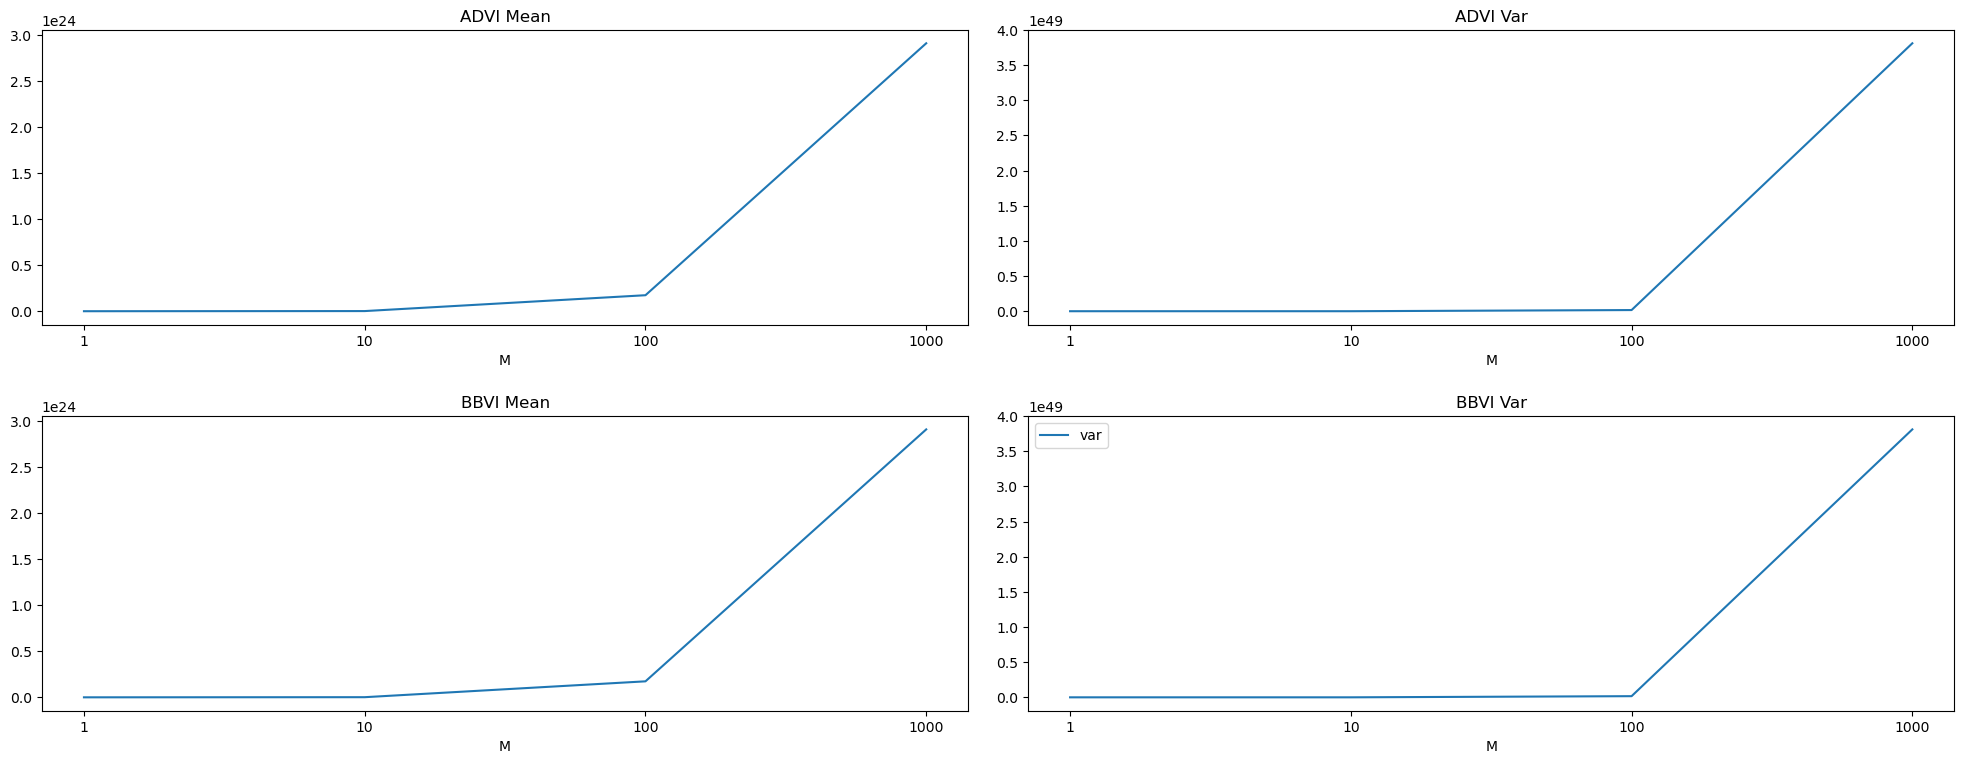

In [51]:
M_list = [1, 10, 100, 1000]
T = 10
p = [0] # Initialize to 0
data = torch.tensor(pd.read_csv("./data.csv", header=None).values.flatten())


def training_trigger():
    bbvi = BBVI(p, "Robbin2")
    advi = ADVI(p, "Robbin2")

    b_list = []
    a_list = []

    for m in M_list:
        for _ in range(T):
            bbvi.update(data, m)
            advi.update(data, m)
        bm = bbvi.compute_mean()
        bv = bbvi.compute_variance()
        am = advi.compute_mean()
        av = advi.compute_variance()

        b_list.append((bm, bv))
        a_list.append((am, av))

    return a_list, b_list

def plot_results():
    a_list, b_list = training_trigger()

    _, axes = plt.subplots(2, 2, figsize = (20,8))

    # bbvi
    axes[1,0].plot(range(len(M_list)), list(map(lambda x: x[0], b_list)),label="mean") # mean
    axes[1,0].set_xticks(range(len(M_list)), M_list) 
    axes[1,0].set_xlabel("M") 
    axes[1,0].set_title("BBVI Mean") 
    axes[1,1].plot(range(len(M_list)), list(map(lambda x: x[1], b_list)), label="var") # var
    axes[1,1].set_xticks(range(len(M_list)), M_list) 
    axes[1,1].set_xlabel("M") 
    axes[1,1].set_title("BBVI Var") 

    # advi
    axes[0,0].plot(range(len(M_list)), list(map(lambda x: x[0], a_list)), label="mean") # mean
    axes[0,0].set_xticks(range(len(M_list)), M_list) 
    axes[0,0].set_xlabel("M") 
    axes[0,0].set_title("ADVI Mean") 
    axes[0,1].plot(range(len(M_list)), list(map(lambda x: x[1], a_list)), label ="var") # var
    axes[0,1].set_xticks(range(len(M_list)), M_list) 
    axes[0,1].set_xlabel("M") 
    axes[0,1].set_title("ADVI Var") 

    plt.tight_layout(pad=2.0)
    plt.legend()
    
plot_results()